# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files  # only needed on Colab

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # X is (batch, words)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() # clear the gradients of the previous step
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

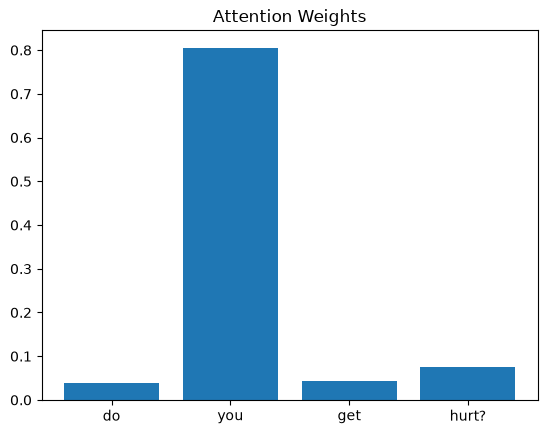

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

'how old are you?'                                 -> highest attention: 'how'        (predicted answer id 1, true 1)
'who created you?'                                 -> highest attention: 'you'        (predicted answer id 3, true 3)
'what do you eat?'                                 -> highest attention: 'eat'        (predicted answer id 7, true 7)


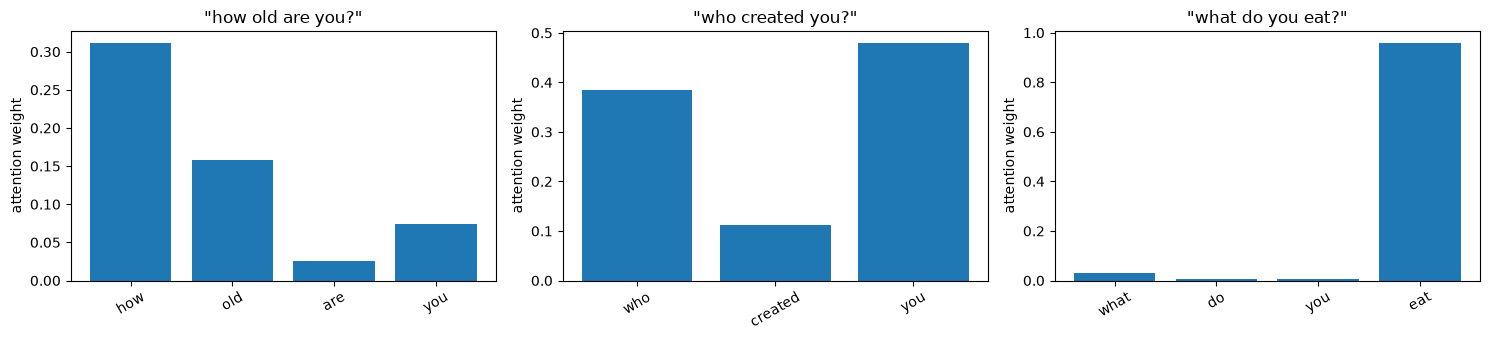

In [7]:
def attention_for(question):
    """Run one question through the trained model and return (words, weights, predicted answer id)."""
    seq = tokenizer.texts_to_sequences([question.lower()])[0]
    words = [tokenizer.index_word[i] for i in seq]
    # pad exactly like the training data so the model sees the same input shape
    x = torch.tensor(pad_sequences([seq], maxlen=X.shape[1], padding="post"), dtype=torch.long)
    with torch.no_grad():
        logits, weights = model(x)
    return words, weights[0, :len(words)].tolist(), logits.argmax(1).item()


# Three questions from three different answer groups
questions = [df["question"][i] for i in [24, 48, 108]]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, q in zip(axes, questions):
    words, w, pred = attention_for(q)
    ax.bar(words, w)
    ax.set_title(f'"{q}"')
    ax.set_ylabel("attention weight")
    ax.tick_params(axis="x", rotation=30)
    top = words[max(range(len(w)), key=w.__getitem__)]
    print(f"{q!r:50} -> highest attention: {top!r:12} (predicted answer id {pred}, true {df.loc[df.question == q, 'answer_id'].iloc[0]})")
plt.tight_layout()
plt.show()

**Answer:** mostly yes. In *"what do you eat?"* the highest weight goes to **eat**, the word that decides the answer
(*I don't need to eat*). In *"how old are you?"* the model focuses on **how** and in *"who created you?"* on **you** – these
are less meaningful on their own, but in an RNN each position's hidden state also summarizes the words before it, so the
last word *you* already "contains" *who created*. All three questions are classified correctly, so the attended positions carry
the information the model needs. The weights are learned only from the answer labels of a small dataset (168 questions),
so attention does not always land on the word a human would choose.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question A: who created you?
Question B: which company made you?
   'who created you?': highest attention -> 'you', predicted answer id = 3
   'which company made you?': highest attention -> 'company', predicted answer id = 3


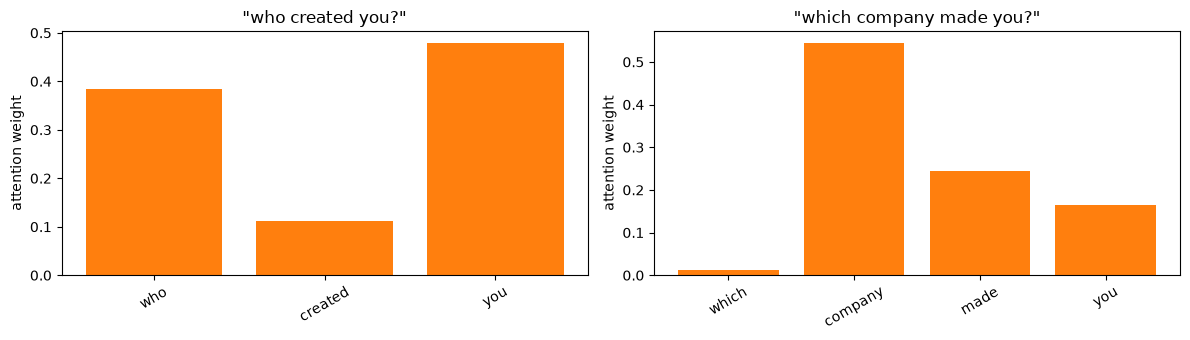

In [8]:
# Two questions with the same answer but different wording
q_a, q_b = df["question"][48], df["question"][53]
print("Question A:", q_a)
print("Question B:", q_b)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, q in zip(axes, [q_a, q_b]):
    words, w, pred = attention_for(q)
    ax.bar(words, w, color="tab:orange")
    ax.set_title(f'"{q}"')
    ax.set_ylabel("attention weight")
    ax.tick_params(axis="x", rotation=30)
    top = words[max(range(len(w)), key=w.__getitem__)]
    print(f"   {q!r}: highest attention -> {top!r}, predicted answer id = {pred}")
plt.tight_layout()
plt.show()

**Answer:** the model focuses on **different words** for the two questions – *you* in "who created you?" and *company* in
"which company made you?" – yet both questions are mapped to the same answer (*People created me*).
This suggests that attention is not looking for one fixed keyword: it gives the most weight to whichever word in *this*
sentence carries the most useful information for the decision, and different wordings can lead to the same answer through
different words. Because the RNN state at each word also contains information about the previous words, a highly weighted
word (such as the final *you*) can represent the meaning of the whole phrase, not only of that single word.